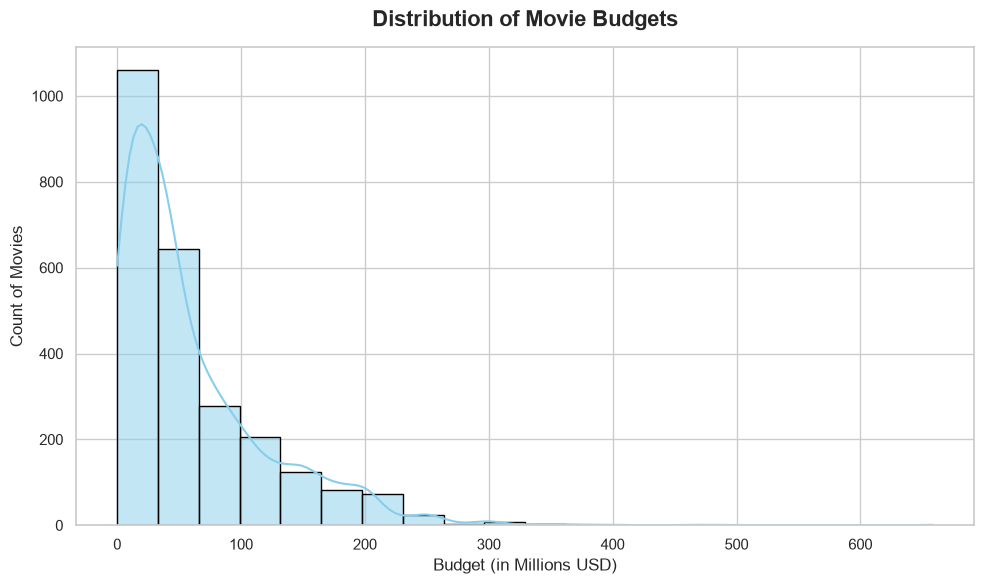

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv(r'C:\AIML Course\Data\Project1\movies_cleaned.csv')

df['budget_millions'] = df['budget'] / 1_000_000

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='budget_millions', bins=20, kde=True, color='skyblue', edgecolor='black')

plt.title("Distribution of Movie Budgets", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Budget (in Millions USD)", fontsize=12)
plt.ylabel("Count of Movies", fontsize=12)

plt.tight_layout()
plt.show()


The distribution is highly right-skewed, showing that the vast majority of movies are heavily concentrated at the lower budget end under $50 million.
There is a steep decline in movie counts as budgets increase; well over 1,000 movies sit in the first bin (0–33M), but fewer than 300 movies manage to cross the $100 million threshold.
A long, sparse tail extends out to nearly $600 million, highlighting that ultra-high-budget mega-blockbusters are exceptionally rare anomalies in the dataset.
The smooth KDE curve peaks sharply below $30 million, reinforcing that the industry standard baseline for production costs trends heavily toward low-to-mid-tier investments.

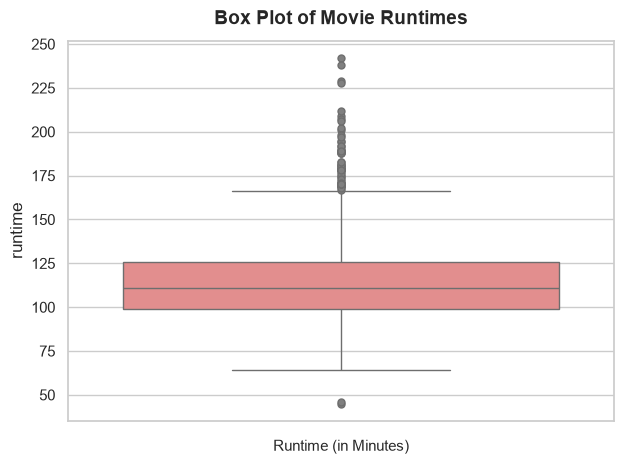

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv(r'C:\AIML Course\Data\Project1\movies_cleaned.csv')

sns.set_theme(style="whitegrid")

sns.boxplot(data=df, y='runtime', color='lightcoral', flierprops={'markerfacecolor': 'grey', 'markersize': 5})
plt.title("Box Plot of Movie Runtimes", fontsize=14, pad=12, fontweight='bold')
plt.xlabel("Runtime (in Minutes)", fontsize=11)

plt.tight_layout()
plt.show()

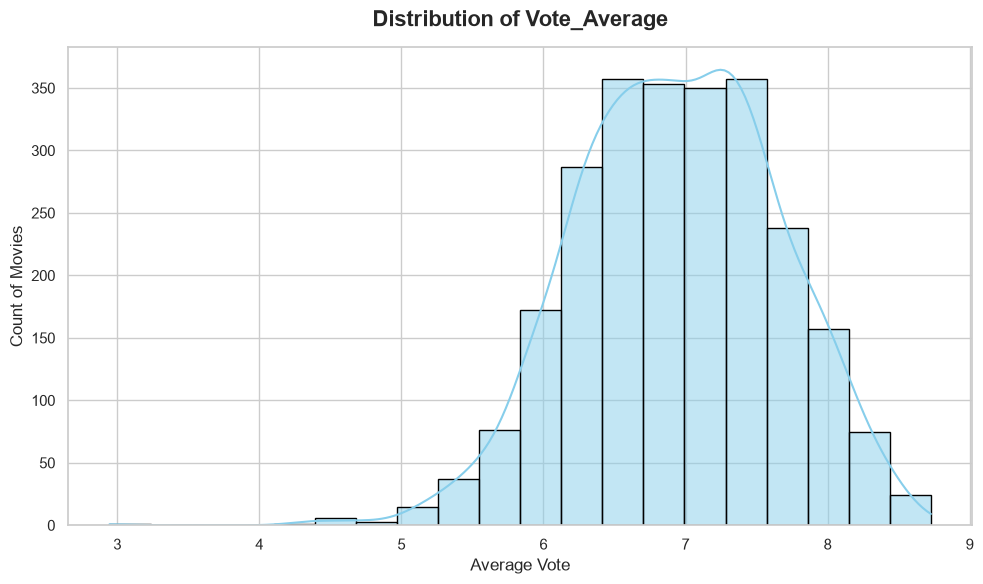

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv(r'C:\AIML Course\Data\Project1\movies_cleaned.csv')

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='vote_average', bins=20, kde=True, color='skyblue', edgecolor='black')

plt.title("Distribution of Vote_Average", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Average Vote", fontsize=12)
plt.ylabel("Count of Movies", fontsize=12)

plt.tight_layout()
plt.show()

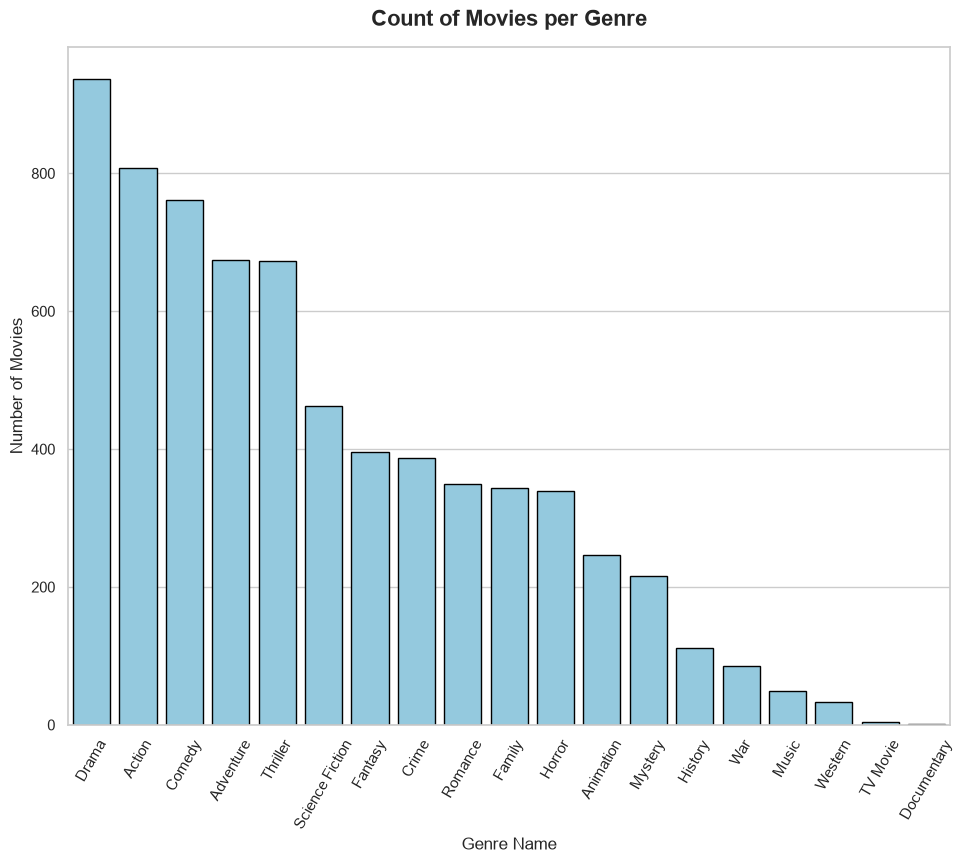

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the datasets
df = pd.read_csv(r'C:\AIML Course\Data\Project1\movie_genres_cleaned.csv')
df1 = pd.read_csv(r'C:\AIML Course\Data\Project1\genres_cleaned.csv')

# Merge datasets to bring in the text names for genres
new_df = pd.merge(df, df1, on='genre_id', how='inner')

# Set a clean plot style
sns.set_theme(style="whitegrid")

# Initialize a taller figure size to comfortably list all genres
plt.figure(figsize=(10, 8))

# FIXED: Swapped 'x' to 'y' to make it horizontal, and matched the order to use genre names
sns.countplot(
    data=new_df, 
    x='genre_name', 
    color='skyblue', 
    edgecolor='black',
    order=new_df['genre_name'].value_counts().index
)

# Add titles and clean labels
plt.title("Count of Movies per Genre", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Genre Name", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)

# Tighten the layout and display
plt.tight_layout()
plt.xticks(rotation=60)
plt.show()


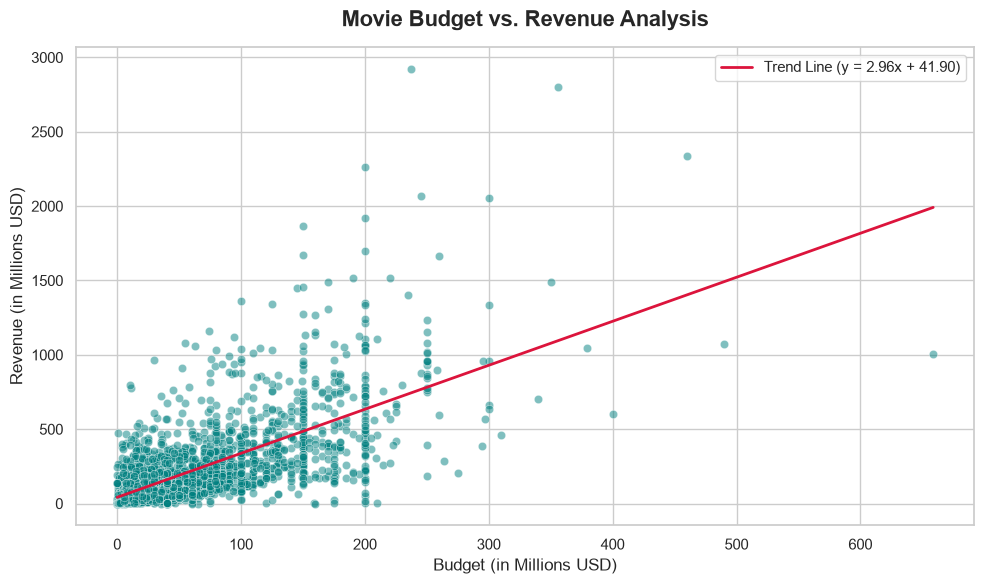

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv(r'C:\AIML Course\Data\Project1\movies_cleaned.csv')

df['budget_millions'] = df['budget'] / 1_000_000
df['revenue_millions'] = df['revenue'] / 1_000_000

df_clean = df.dropna(subset=['budget_millions', 'revenue_millions'])

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean, 
    x='budget_millions', 
    y='revenue_millions', 
    color='teal',
    alpha=0.5,
    edgecolor='w'
)

m, c = np.polyfit(df_clean['budget_millions'], df_clean['revenue_millions'], 1)

x_vals = np.linspace(df_clean['budget_millions'].min(), df_clean['budget_millions'].max(), 100)
y_vals = m * x_vals + c

plt.plot(x_vals, y_vals, color='crimson', linewidth=2, label=f'Trend Line (y = {m:.2f}x + {c:.2f})')

plt.title("Movie Budget vs. Revenue Analysis", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Budget (in Millions USD)", fontsize=12)
plt.ylabel("Revenue (in Millions USD)", fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()



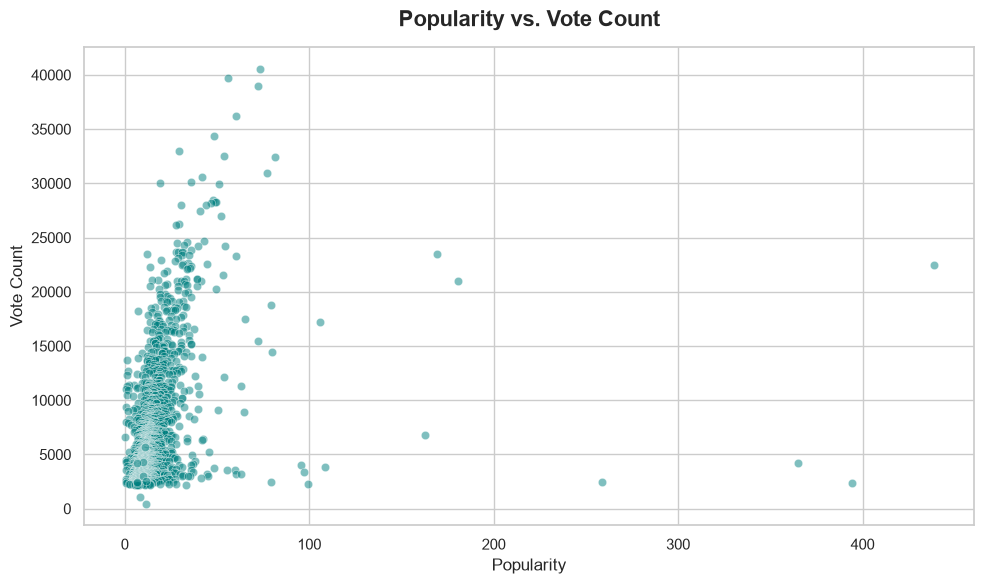

In [44]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the dataset
df = pd.read_csv(r'C:\AIML Course\Data\Project1\movies_cleaned.csv')

# Set a clean plot style
sns.set_theme(style="whitegrid")

# Initialize the figure size
plt.figure(figsize=(10, 6))

# Generate the scatter plot
sns.scatterplot(
    data=df, 
    x='popularity', 
    y='vote_count', 
    color='teal',
    alpha=0.5,
    edgecolor='w'
)

# Add clear titles and labels
plt.title("Popularity vs. Vote Count", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Popularity", fontsize=12)
plt.ylabel("Vote Count", fontsize=12)

# REMOVED: plt.legend() since there are no labeled series, avoiding a warning message

# Tighten the layout and display
plt.tight_layout()
plt.show()


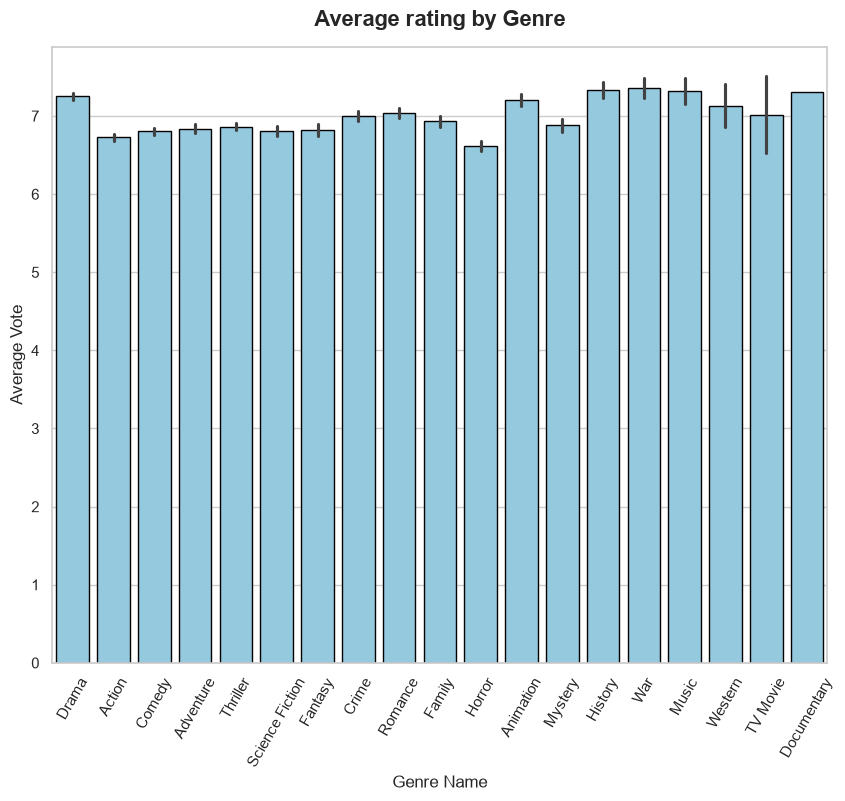

In [46]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the datasets
df = pd.read_csv(r'C:\AIML Course\Data\Project1\movie_genres_cleaned.csv')
df1 = pd.read_csv(r'C:\AIML Course\Data\Project1\genres_cleaned.csv')
df2 = pd.read_csv(r'C:\AIML Course\Data\Project1\movies_cleaned.csv')

# Merge datasets to bring in the text names for genres
new_df = pd.merge(df, df1, on='genre_id', how='inner')
final_df = pd.merge(new_df, df2, on= 'movie_id', how='inner')

# Set a clean plot style
sns.set_theme(style="whitegrid")

# Initialize a taller figure size to comfortably list all genres
plt.figure(figsize=(10, 8))

# FIXED: Swapped 'x' to 'y' to make it horizontal, and matched the order to use genre names
sns.barplot(
    data=final_df, 
    x='genre_name',
    y='vote_average', 
    color='skyblue', 
    edgecolor='black',
    order=new_df['genre_name'].value_counts().index
)

# Add titles and clean labels
plt.title("Average rating by Genre", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Genre Name", fontsize=12)
plt.ylabel("Average Vote", fontsize=12)

plt.xticks(rotation=60)
plt.show()




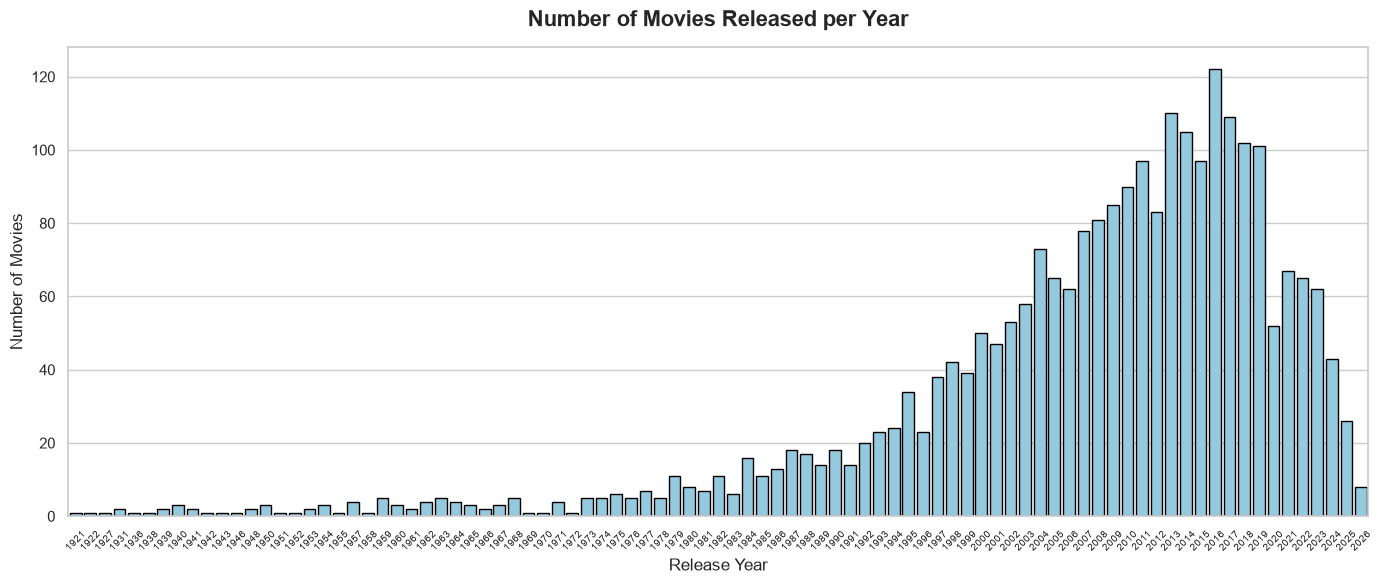

In [50]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv(r"C:\AIML Course\Data\Project1\movies_cleaned.csv")

df['Release Date'] = pd.to_datetime(df['release_date'])

movies_per_year = df['Release Date'].dt.year.value_counts().sort_index()

movies_per_year_df = movies_per_year.reset_index()
movies_per_year_df.columns = ['Release Year', 'No of Movies']

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

sns.barplot(
    data=movies_per_year_df, 
    x='Release Year',
    y='No of Movies', 
    color='skyblue', 
    edgecolor='black'
)

plt.title("Number of Movies Released per Year", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)

plt.xticks(rotation=45, fontsize=7)

plt.tight_layout()
plt.show()


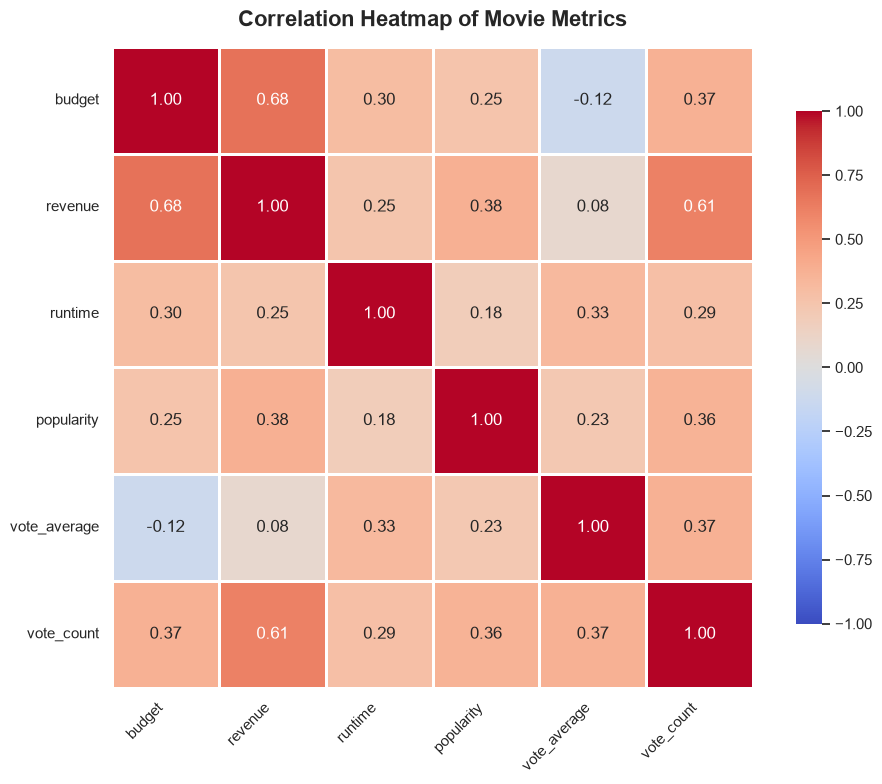

In [51]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the dataset
df = pd.read_csv(r"C:\AIML Course\Data\Project1\movies_cleaned.csv")

# Select the specific numerical columns for correlation
cols = ['budget', 'revenue', 'runtime', 'popularity', 'vote_average', 'vote_count']
corr_matrix = df[cols].corr()

# Set a clean plot style
sns.set_theme(style="white")

# Initialize the figure size
plt.figure(figsize=(10, 8))

# Plot the heatmap
sns.heatmap(
    corr_matrix, 
    annot=True,            # Display the correlation values inside the squares
    fmt=".2f",             # Format numbers to 2 decimal places
    cmap="coolwarm",       # Diverging color palette (blue = negative, red = positive)
    vmin=-1, vmax=1,       # Fix color scale bounds between -1 and 1
    center=0,              # Center the neutral color at 0
    linewidths=1,          # Add clean white borders between cells
    square=True,           # Force each cell to be a neat square
    cbar_kws={"shrink": 0.8}
)

# Add title and adjust label formatting
plt.title("Correlation Heatmap of Movie Metrics", fontsize=16, pad=15, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)

# Tighten the layout and display
plt.tight_layout()
plt.show()


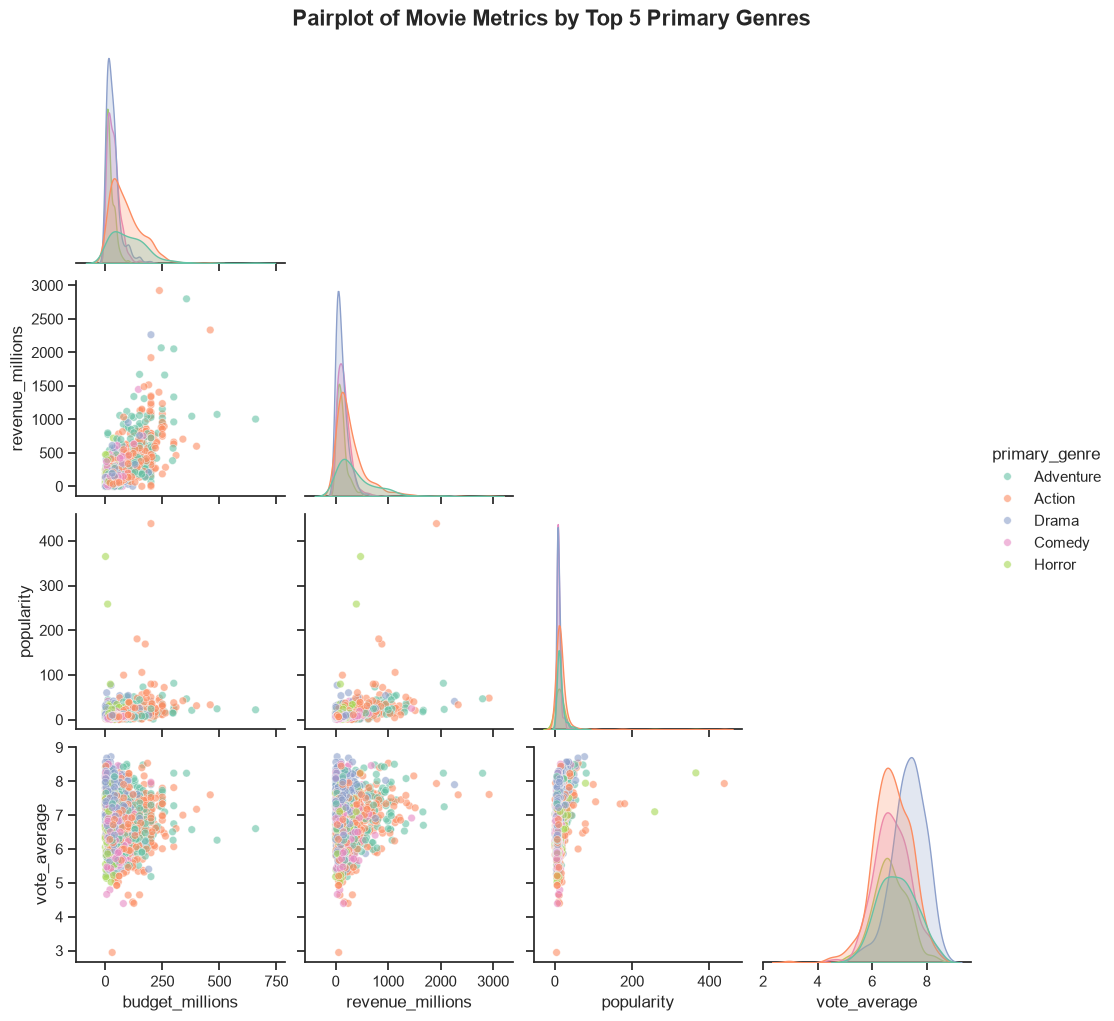

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the datasets
movies = pd.read_csv(r"C:\AIML Course\Data\Project1\movies_cleaned.csv")
movie_genres = pd.read_csv(r"C:\AIML Course\Data\Project1\movie_genres_cleaned.csv")
genres = pd.read_csv(r"C:\AIML Course\Data\Project1\genres_cleaned.csv")

# Merge genre names onto movie_genres and keep the first listed genre per movie as 'primary_genre'
genres_merged = pd.merge(movie_genres, genres, on='genre_id', how='inner')
primary_genres = genres_merged.drop_duplicates(subset='movie_id', keep='first')[['movie_id', 'genre_name']]
primary_genres.rename(columns={'genre_name': 'primary_genre'}, inplace=True)

# Merge primary genre into the main movies dataframe
df = pd.merge(movies, primary_genres, on='movie_id', how='inner')

# Optional: Filter to the top 5 most common genres so the color legend stays readable
top_genres = df['primary_genre'].value_counts().nlargest(5).index
df_filtered = df[df['primary_genre'].isin(top_genres)].copy()

# Scale budget and revenue to millions for cleaner axis labels
df_filtered['budget_millions'] = df_filtered['budget'] / 1_000_000
df_filtered['revenue_millions'] = df_filtered['revenue'] / 1_000_000

# Select the columns to plot
plot_cols = ['budget_millions', 'revenue_millions', 'popularity', 'vote_average', 'primary_genre']

# Set visual theme
sns.set_theme(style="ticks")

# Generate the pairplot
g = sns.pairplot(
    data=df_filtered[plot_cols],
    hue='primary_genre',
    palette='Set2',
    diag_kind='kde',          # Smooth density curves on the diagonal
    plot_kws={'alpha': 0.6, 's': 30, 'edgecolor': 'w'},
    corner=True               # Hides redundant upper-triangle plots for faster rendering
)

# Add a clean overall title
g.fig.suptitle("Pairplot of Movie Metrics by Top 5 Primary Genres", y=1.02, fontsize=16, fontweight='bold')

plt.show()


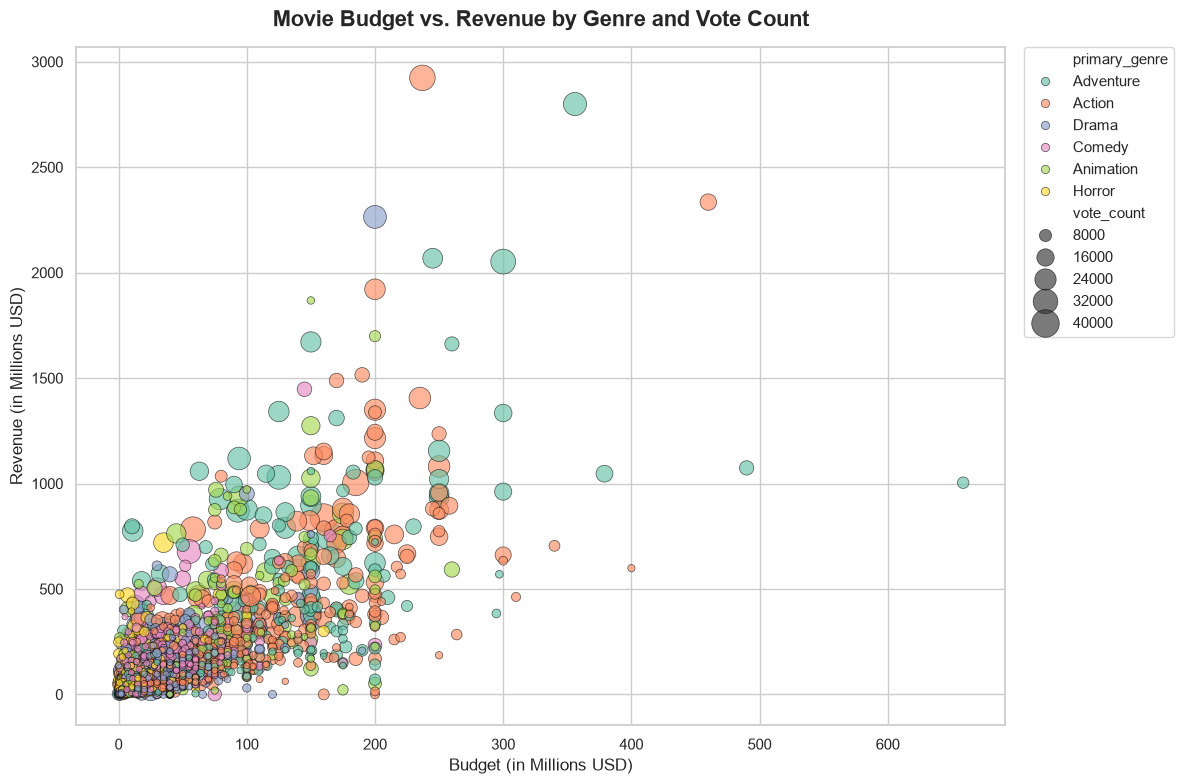

In [54]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the datasets
movies = pd.read_csv(r"C:\AIML Course\Data\Project1\movies_cleaned.csv")
movie_genres = pd.read_csv(r"C:\AIML Course\Data\Project1\movie_genres_cleaned.csv")
genres = pd.read_csv(r"C:\AIML Course\Data\Project1\genres_cleaned.csv")

# Extract each movie's primary genre (first listed genre per movie)
genres_merged = pd.merge(movie_genres, genres, on='genre_id', how='inner')
primary_genres = genres_merged.drop_duplicates(subset='movie_id', keep='first')[['movie_id', 'genre_name']]
primary_genres.rename(columns={'genre_name': 'primary_genre'}, inplace=True)

# Merge primary genre onto the movies dataframe
df = pd.merge(movies, primary_genres, on='movie_id', how='inner')

# Scale budget and revenue to millions for clean axis labels
df_filtered['budget_millions'] = df_filtered['budget'] / 1_000_000
df_filtered['revenue_millions'] = df_filtered['revenue'] / 1_000_000

# Set a clean visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# Plot scatter with hue (color) and size (bubble area)
sns.scatterplot(
    data=df_filtered,
    x='budget_millions',
    y='revenue_millions',
    hue='primary_genre',
    size='vote_count',
    sizes=(20, 400),        # Controls minimum and maximum dot sizes
    palette='Set2',
    alpha=0.65,
    edgecolor='black',
    linewidth=0.5
)

# Add titles and axis labels
plt.title("Movie Budget vs. Revenue by Genre and Vote Count", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Budget (in Millions USD)", fontsize=12)
plt.ylabel("Revenue (in Millions USD)", fontsize=12)

# Move the legend outside the plot area so it does not cover data points
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, frameon=True)

plt.tight_layout()
plt.show()


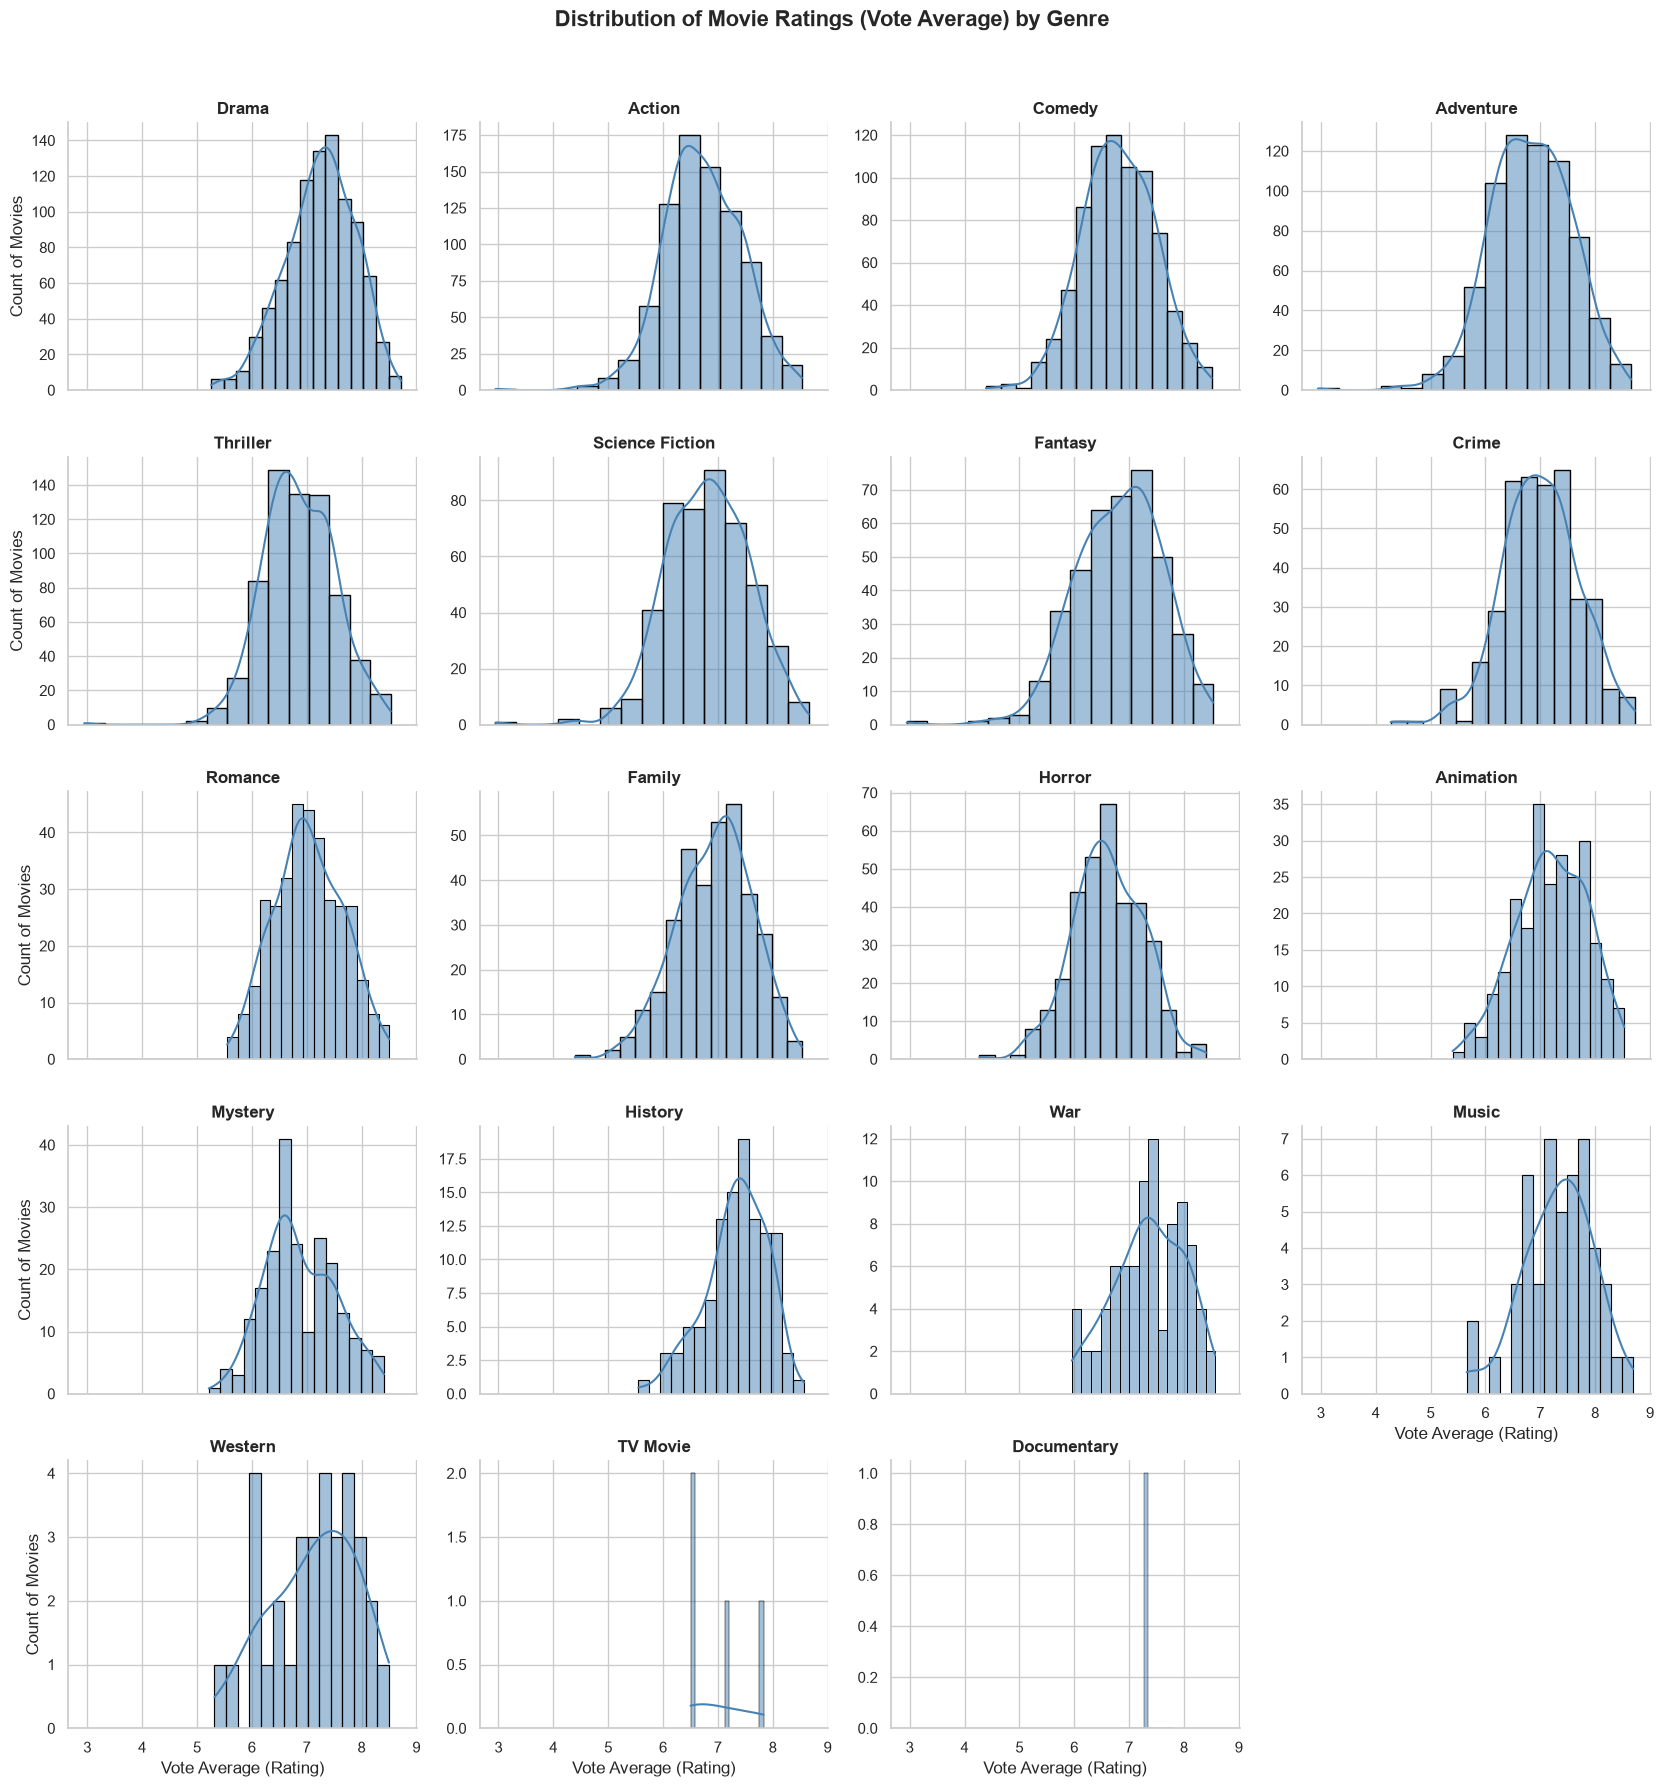

In [56]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the datasets
movies = pd.read_csv(r"C:\AIML Course\Data\Project1\movies_cleaned.csv")
movie_genres = pd.read_csv(r"C:\AIML Course\Data\Project1\movie_genres_cleaned.csv")
genres = pd.read_csv(r"C:\AIML Course\Data\Project1\genres_cleaned.csv")

# Merge genre names onto movie_genres and keep all genre associations per movie
genres_merged = pd.merge(movie_genres, genres, on='genre_id', how='inner')
df = pd.merge(movies, genres_merged[['movie_id', 'genre_name']], on='movie_id', how='inner')

# Sort genres alphabetically or by movie count for a clean grid order
genre_order = df['genre_name'].value_counts().index

# Set a clean visual style
sns.set_theme(style="whitegrid")

# Initialize the FacetGrid
# col_wrap=4 places 4 panels per row; sharey=False lets smaller genres scale clearly
g = sns.FacetGrid(
    data=df, 
    col='genre_name', 
    col_order=genre_order,
    col_wrap=4, 
    height=3.5, 
    aspect=1.2,
    sharey=False
)

# Map a histogram with a smooth KDE curve onto each panel
g.map_dataframe(
    sns.histplot, 
    x='vote_average', 
    bins=15, 
    kde=True, 
    color='steelblue', 
    edgecolor='black'
)

# Customize panel titles and axis labels
g.set_titles(col_template="{col_name}", size=12, weight='bold')
g.set_axis_labels("Vote Average (Rating)", "Count of Movies")

# Add an overall main title above the grid
g.fig.suptitle("Distribution of Movie Ratings (Vote Average) by Genre", y=1.02, fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()


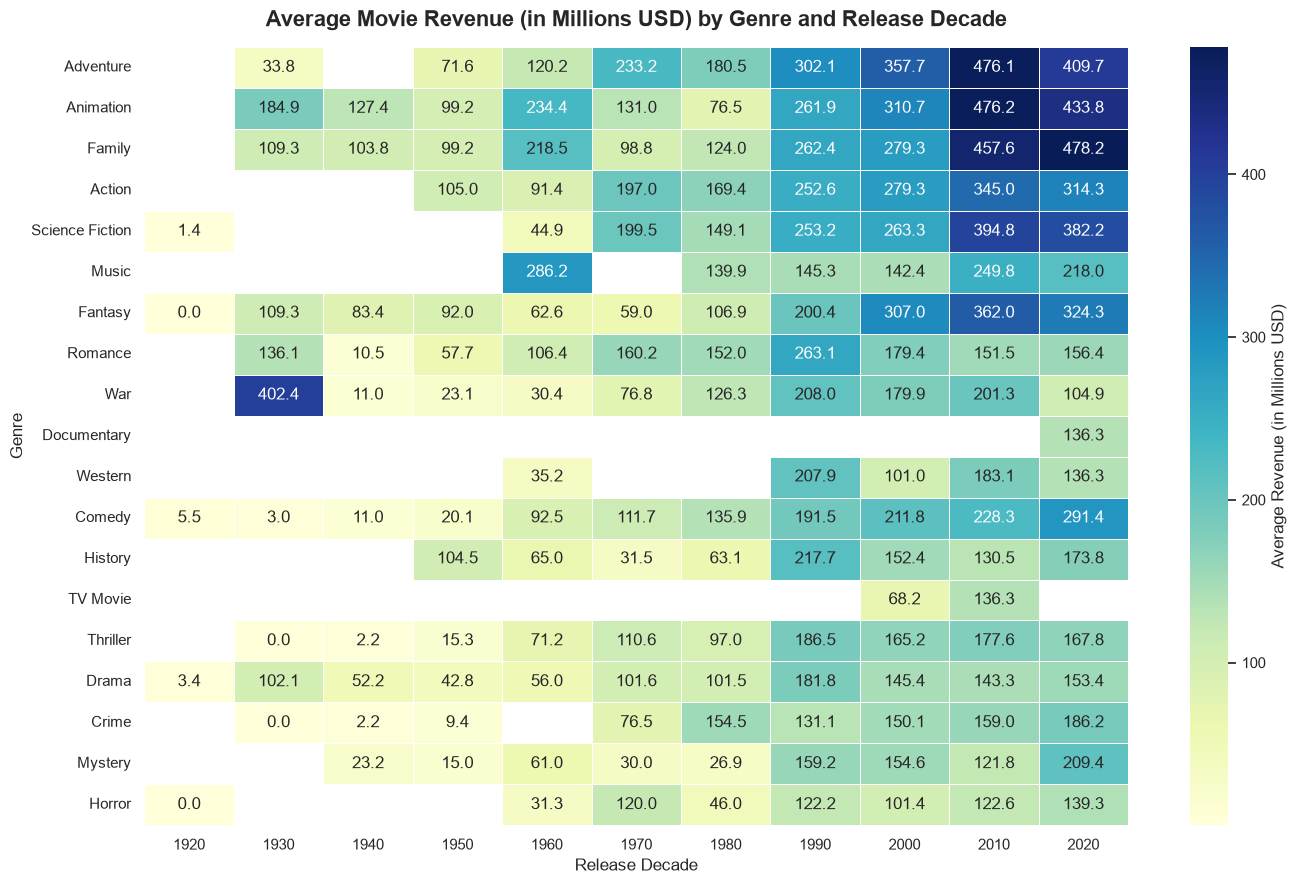

In [57]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the datasets
movies = pd.read_csv(r"C:\AIML Course\Data\Project1\movies_cleaned.csv")
movie_genres = pd.read_csv(r"C:\AIML Course\Data\Project1\movie_genres_cleaned.csv")
genres = pd.read_csv(r"C:\AIML Course\Data\Project1\genres_cleaned.csv")

# Merge genre names onto movies
genres_merged = pd.merge(movie_genres, genres, on='genre_id', how='inner')
df = pd.merge(movies, genres_merged[['movie_id', 'genre_name']], on='movie_id', how='inner')

# Convert release_date to datetime and extract the decade (e.g., 1994 -> 1990)
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df = df.dropna(subset=['release_date'])
df['decade'] = (df['release_date'].dt.year // 10) * 10

# Scale revenue to millions USD for clean readability inside heatmap cells
df['revenue_millions'] = df['revenue'] / 1_000_000

# Create a pivot table of average revenue (Genres as rows, Decades as columns)
pivot_table = df.pivot_table(
    values='revenue_millions', 
    index='genre_name', 
    columns='decade', 
    aggfunc='mean'
)

# Sort genres by overall highest average revenue so top earners appear at the top
pivot_table = pivot_table.loc[pivot_table.mean(axis=1).sort_values(ascending=False).index]

# Set a clean visual style
sns.set_theme(style="white")
plt.figure(figsize=(14, 9))

# Plot the heatmap
sns.heatmap(
    pivot_table, 
    annot=True,            # Display the average revenue value inside each cell
    fmt=".1f",             # Format numbers to 1 decimal place (e.g., 145.2)
    cmap="YlGnBu",         # Sequential color map (light yellow = low, deep blue = high)
    linewidths=0.5,        # Thin grid lines separating cells
    cbar_kws={'label': 'Average Revenue (in Millions USD)'}
)

# Add titles and clean axis labels
plt.title("Average Movie Revenue (in Millions USD) by Genre and Release Decade", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Release Decade", fontsize=12)
plt.ylabel("Genre", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()
